In [ ]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad

import matplotlib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import math

import scipy
import random
import statistics
import umap as UM
from scipy.stats import zscore
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans
from sklearn.cluster import SpectralClustering
import seaborn as sns
from IPython.display import clear_output
import muon


''' 
loading MBTA 
'''
import sys
sys.path.append('path to utils_MBTA and common_utils')
# from utils_MBTA import *
import utils_MBTA
import common_utils

import importlib
importlib.reload(utils_MBTA)
importlib.reload(common_utils)

/michorlab/bingxian/miniforge3/envs/dev/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<module 'common_utils' from '/michorlab/bingxian/multi_modal_unpaired_matching/common_utils.py'>

In [ ]:
''' 
read h5ad files
'''
dir1 = ".h5ad"
dir2 = ".h5ad"

mod1 = sc.read_h5ad(dir1)
mod2 = sc.read_h5ad(dir2)

mod1.X = mod1.X.toarray() if hasattr(mod1.X, "toarray") else mod1.X
mod2.X = mod2.X.toarray() if hasattr(mod2.X, "toarray") else mod2.X  # binarize for atac

mod2.X = (mod2.X >0).astype(np.float32)

sc.pp.normalize_total(mod1, target_sum=1e4)
sc.pp.log1p(mod1)

mod1_tensor = torch.tensor(mod1.X).type(torch.float32)
mod2_tensor = torch.tensor(mod2.X).type(torch.float32)

idx = random.sample(range(mod1_tensor.shape[0]), 500)
remaining_idx = np.setdiff1d(np.arange(mod1_tensor.shape[0]), idx)

mod1_tensor_test = mod1_tensor[idx,:]
mod1_tensor = mod1_tensor[remaining_idx,:]

mod2_tensor_test = mod2_tensor[idx,:]
mod2_tensor = mod2_tensor[remaining_idx,:]

test_set_index = idx.copy()


In [ ]:
''' 
training for MBTA VAEs
'''
# scRNA is usually quick, takes 10mins 
# ATAC-seq or others can be slower depending on feature dimension

model_mod1 = utils_MBTA.train_model(mod1_tensor,
                                Nnodes = 200, #ori 200
                                latent_dim = 20, # ori is 20
                                batchSize = 150,
                                Ndir = 50, Niter = 20000 )

print("done with RNA")
model_mod2 = utils_MBTA.train_model(mod2_tensor,
                                Nnodes = 200, #ori 200
                                latent_dim = 20, # ori is 10
                                batchSize = 150,
                                Ndir = 50, Niter = 20000, balance = True, neg_ratio = 1, fixval=0.05, positive=False)


Iter: 19000, loss_re: 23046.8242, loss_pcf: 0.0000
reconstruction loss = 152.56755


In [ ]:
''' 
training of the flow matching component of MBTA
'''

# this part is faster, each pairing model takes less than 30 mins

m1 = utils_MBTA.MBTA_submodule(model_mod1, "MBTA", "RNA")
m2 = utils_MBTA.MBTA_submodule(model_mod2, "MBTA", "ATAC")

MBTA = utils_MBTA.paired_MBTA(m1, m2)
MBTA.paired_training(mod1_tensor, mod2_tensor,  Nitr=50000)
MBTA.paired_training(mod1_tensor, mod2_tensor,  Nitr=50000, Dir = 2)
clear_output()

# generating translated data
a = MBTA.generate(m2.model.latentMean(mod2_tensor_test), m1.model.latentMean(mod1_tensor_test), Dir = 2)
b = MBTA.generate(m1.model.latentMean(mod1_tensor_test), m2.model.latentMean(mod2_tensor_test))


In [7]:


pca_low = PCA(n_components = 50, random_state = 1)
reducer2 = UM.UMAP(n_neighbors=10, 
                  metric = 'euclidean', 
                  repulsion_strength=.1, 
                  n_epochs=500, 
                  negative_sample_rate=5, 
                  min_dist = .5,
                  verbose = False,
                  random_state=1,
                  n_components = 2
                 )


pca_methyl = PCA(n_components = 500, random_state = 1)


/michorlab/bingxian/miniforge3/envs/dev/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


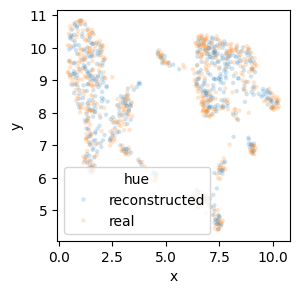

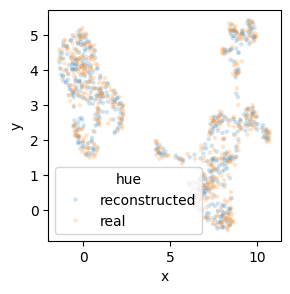

In [8]:
df1 = common_utils.common_embedding(reducer2, pca_low, m1.predict(mod1_tensor_test), mod1_tensor_test.detach().numpy())
df2 = common_utils.common_embedding(reducer2, pca_low, m2.predict(mod2_tensor_test), mod2_tensor_test.detach().numpy())

sns.scatterplot(df1, x = 'x', y = 'y', hue = 'hue', linewidth = 0, s = 10, alpha = .2)
plt.gcf().set_size_inches(3,3)

plt.show()
sns.scatterplot(df2, x = 'x', y = 'y', hue = 'hue', linewidth = 0, s = 10, alpha = .2)
plt.gcf().set_size_inches(3,3)

plt.show()

(np.float64(-1.0769646629691123),
 np.float64(12.597445683181286),
 np.float64(2.7119041442871095),
 np.float64(11.467802429199219))

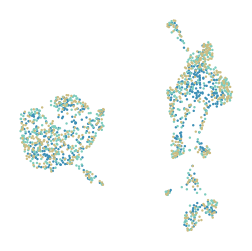

In [11]:
recon_palette = {'reconstructed':"#3c8fb6", 
                 'translated': '#7dccbe',
                 'real': "#ccbd83" }

recon_palette2 = {'reconstructed':"#4d65a8", 
                 'translated': '#6e8fc2',
                 'real': "#c2b43a" }

df1 = common_utils.common_embedding_3(reducer2, pca_low, m1.predict(mod1_tensor_test), mod1_tensor_test.detach().numpy(), a)
sns.scatterplot(df1, x = 'x', y = 'y', hue = 'hue', linewidth = 0, s = 3, alpha = 1,  palette= recon_palette, legend = False)
plt.gcf().set_size_inches(3,3)
plt.axis('off')